# Compare executed CatBoost vs MLP vs sequence-model experiments

**No scores are hardcoded.** This notebook reads the actual `comparison.csv` files written after executing `01_CO2_final.ipynb`, `02_ETTh1_final.ipynb` and `03_Jena_Weather_NEW.ipynb`.

The experiments use distinct target units and forecast horizons, so compare **percentage differences within each dataset**, not raw ppm vs °C. We also show the model selected by *validation*, rather than selecting an apparently strongest model using test data.

The optional **Tourism Monthly global-panel** notebook uses per-series MASE, not single-series RMSE, so it gets a *separate* comparison block below.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

root=Path('forecast_challenge_outputs')
expected=['co2','etth1','jena']
missing=[name for name in expected if not (root/name/'comparison.csv').exists()]
if missing:
    raise FileNotFoundError('Run the experiment notebooks first. Missing CSV(s): '+', '.join(str(root/x/'comparison.csv') for x in missing))
frames=[]
configs={}
for ds in expected:
    p=root/ds/'comparison.csv'
    d=pd.read_csv(p)
    required={'model','family','rmse','val_rmse'}
    assert required.issubset(d.columns),f'Missing result columns in {p}'
    config_file=root/ds/'run_info.json'
    if not config_file.exists():raise FileNotFoundError(f'Missing run metadata {config_file}')
    cfg=json.loads(config_file.read_text())
    assert cfg['dataset']==ds
    configs[ds]=cfg
    d['dataset']=ds
    frames.append(d)
all_results=pd.concat(frames,ignore_index=True)
display(all_results[['dataset','model','family','val_rmse','rmse']].sort_values(['dataset','rmse']).round(4))

,dataset,model,family,val_rmse,rmse
0,co2,CatBoost (relative),Tree,0.5146,0.4925
1,co2,CatBoost (engineered),Tree,0.5232,0.5106
2,co2,LSTM,Neural,0.5312,0.5164
3,co2,MLP,Neural,0.4784,0.5252
4,co2,Patch Transformer,Neural,0.5454,0.5322
5,co2,GRU,Neural,0.5440,0.5328
6,co2,N-BEATS-style,Neural,0.4835,0.5419
7,co2,TCN,Neural,0.4881,0.5526
8,co2,Linear,Neural,0.6169,0.6460
9,co2,CNN1D,Neural,0.7322,0.7947


## Within-dataset comparisons

Percent difference = `100 × (model test RMSE / same-dataset MLP test RMSE − 1)`. Negative values indicate lower error than the MLP. No claim about uncertainty or statistical significance is made from this single test split.

,dataset,model,rmse,pct_vs_mlp
0,co2,CatBoost (relative),0.493,-6.225
1,co2,CatBoost (engineered),0.511,-2.778
2,co2,LSTM,0.516,-1.672
3,co2,MLP,0.525,0.000
4,co2,Patch Transformer,0.532,1.330
5,co2,GRU,0.533,1.437
6,co2,N-BEATS-style,0.542,3.177
7,co2,TCN,0.553,5.211
8,co2,Linear,0.646,23.002
9,co2,CNN1D,0.795,51.308


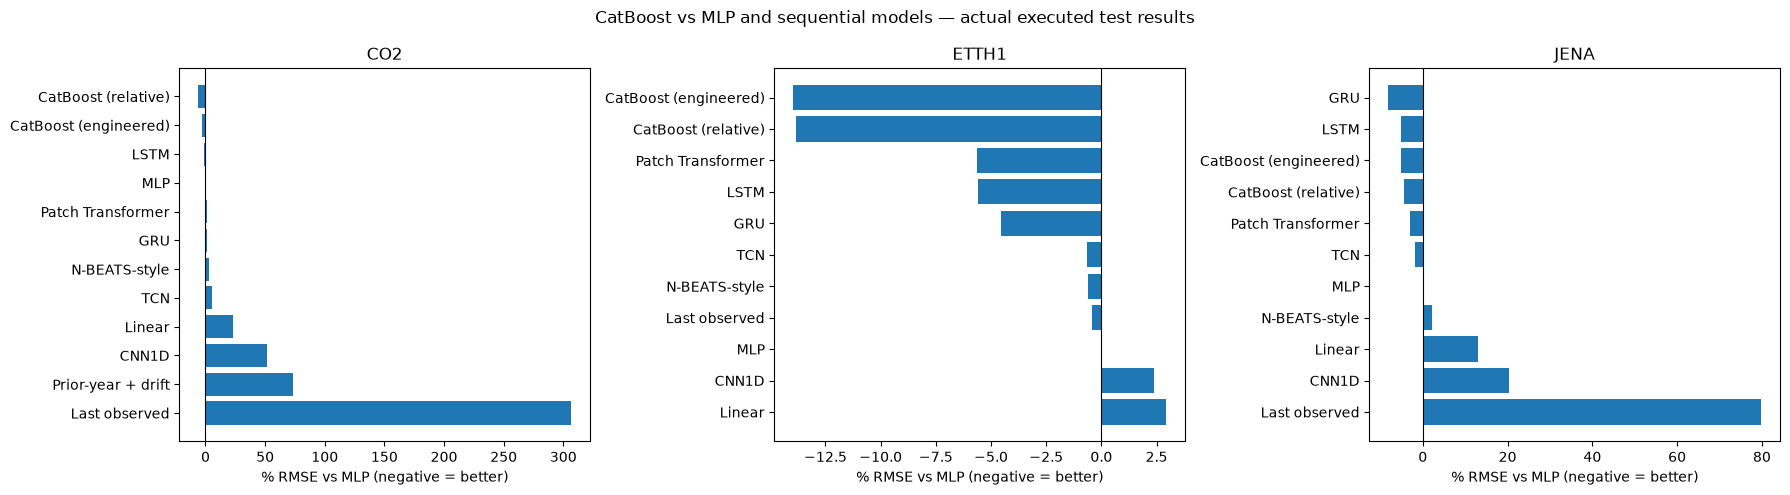

In [2]:
mlp=all_results.loc[all_results.model=='MLP',['dataset','rmse']].rename(columns={'rmse':'mlp_rmse'})
comparison=all_results.merge(mlp,on='dataset',validate='many_to_one')
comparison['pct_vs_mlp']=100*(comparison.rmse/comparison.mlp_rmse-1)
display(comparison[['dataset','model','rmse','pct_vs_mlp']].sort_values(['dataset','pct_vs_mlp']).round(3))
fig,axs=plt.subplots(1,len(expected),figsize=(18,5),sharex=False)
for ax,ds in zip(axs,expected):
    d=comparison.query('dataset == @ds').sort_values('pct_vs_mlp')
    ax.barh(d.model,d.pct_vs_mlp)
    ax.axvline(0,color='black',linewidth=.8)
    ax.set_title(ds.upper());ax.set_xlabel('% RMSE vs MLP (negative = better)')
    ax.invert_yaxis()
fig.suptitle('CatBoost vs MLP and sequential models — actual executed test results')
plt.tight_layout()
plt.savefig('comparison_vs_mlp.png',dpi=170,bbox_inches='tight');plt.show()

## Validation-selected champions (less test-selection bias)

For each dataset, select the best **neural** and best **relative-target CatBoost** variant using *validation RMSE* only, then compare their *held-out test RMSE*. This is not multi-seed statistical evidence, but it avoids silently choosing a winner from test data.

In [3]:
rows=[]
for ds in expected:
    x=all_results.query('dataset == @ds')
    neural=x.query("family == 'Neural'").sort_values('val_rmse').iloc[0]
    tree=x[(x.family=='Tree') & (x.model!='CatBoost (raw level)')].sort_values('val_rmse').iloc[0]
    rows.append({'dataset':ds,'selected_neural':neural.model,'neural_val_rmse':neural.val_rmse,
                 'neural_test_rmse':neural.rmse,'selected_catboost':tree.model,
                 'catboost_val_rmse':tree.val_rmse,'catboost_test_rmse':tree.rmse,
                 'neural_vs_catboost_pct':100*(neural.rmse/tree.rmse-1),
                 'unit':configs[ds]['unit']})
champions=pd.DataFrame(rows)
display(champions.round(4))
champions.to_csv('validation_selected_comparison.csv',index=False)
print('Negative neural_vs_catboost_pct means the validation-selected neural model wins that test period.')

,dataset,selected_neural,neural_val_rmse,neural_test_rmse,selected_catboost,catboost_val_rmse,catboost_test_rmse,neural_vs_catboost_pct,unit
0,co2,MLP,0.4784,0.5252,CatBoost (relative),0.5146,0.4925,6.6378,ppm
1,etth1,CNN1D,1.6026,2.0460,CatBoost (engineered),1.5458,1.7192,19.0115,°C
2,jena,GRU,2.3047,2.1654,CatBoost (engineered),2.3563,2.2386,-3.2659,°C


Negative neural_vs_catboost_pct means the validation-selected neural model wins that test period.


## Publication checklist

- Link all executed notebook files and `comparison.csv` outputs (not only a screenshot of graphs).
- Disclose that Jena was selected *before* running these held-out tests, not because of favorable results.
- Explain that temperature (°C) and CO₂ (ppm) RMSE are different units and that horizon length also differs.
- Interpret engineered CatBoost as a different **feature pipeline**, not a pure architecture contest.
- Stronger claims require multiple seeds, rolling periods, tuning-budget sensitivity, and uncertainty estimates for overlapping forecast windows.
- Tourism Monthly is an independent global multi-series experiment; do **not** compare its MASE with the RMSE of the other datasets. The published Transformer vs CatBoost figures were obtained under different settings and should never be shown as if reproduced here.


## Tourism Monthly (if executed): global MASE comparison

This section is independent because Tourism Monthly evaluates **366 series** using **mean MASE** rather than single-target RMSE. If the Tourism CSV is absent, it displays instructions, not invented scores. The external Hugging Face comparison is background, **not** a reproduced result.

,model,family,val_mase,mase,smape,train_seconds
0,MLP,Neural,1.8220,1.6752,20.0539,5.24
1,TCN,Neural,1.9035,1.7184,20.1301,7.14
2,Patch Transformer,Neural,1.8865,1.7583,20.4661,30.97
3,Seasonal naive,Naive,1.9951,1.7805,21.6699,0.00
4,CatBoost (raw lags),Tree,1.8983,1.8742,20.8416,52.81
5,CatBoost (engineered),Tree,1.9398,1.9464,21.5404,60.41
6,LSTM,Neural,2.0914,2.0349,22.8597,20.82
7,GRU,Neural,2.1902,2.1149,23.3159,24.16


,model,mase,pct_mase_vs_mlp
0,MLP,1.675,0.000
1,TCN,1.718,2.584
2,Patch Transformer,1.758,4.965
3,Seasonal naive,1.781,6.291
4,CatBoost (raw lags),1.874,11.883
5,CatBoost (engineered),1.946,16.194
6,LSTM,2.035,21.476
7,GRU,2.115,26.249


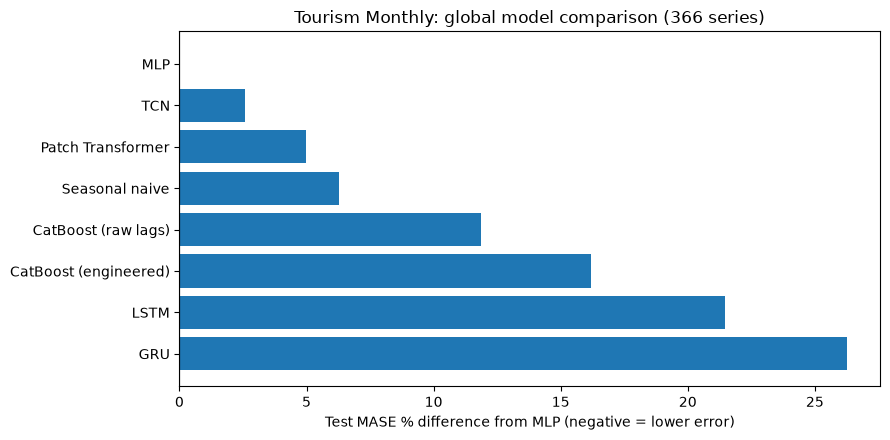

Validation-selected Tourism model: MLP | test MASE: 1.6752


In [4]:
tourism_path=root/'tourism_monthly'/'comparison.csv'
if not tourism_path.exists():
    print('No Tourism Monthly results yet. Run 05_Tourism_Monthly_GLOBAL_NEW.ipynb first.')
else:
    d=pd.read_csv(tourism_path)
    assert {'model','family','mase','val_mase'}.issubset(d.columns)
    display(d[['model','family','val_mase','mase','smape','train_seconds']].sort_values('mase').round(4))
    mlp=float(d.loc[d.model=='MLP','mase'].iloc[0])
    d['pct_mase_vs_mlp']=100*(d.mase/mlp-1)
    display(d[['model','mase','pct_mase_vs_mlp']].sort_values('pct_mase_vs_mlp').round(3))
    fig,ax=plt.subplots(figsize=(9,4.5))
    ordered=d.sort_values('pct_mase_vs_mlp',ascending=False)
    ax.barh(ordered.model,ordered.pct_mase_vs_mlp)
    ax.axvline(0,color='black',lw=.8)
    ax.set(xlabel='Test MASE % difference from MLP (negative = lower error)',
           title='Tourism Monthly: global model comparison (366 series)')
    fig.tight_layout();fig.savefig('tourism_mase_vs_mlp.png',dpi=150);plt.show()
    selected=d[d.family!='Naive'].sort_values('val_mase').iloc[0]
    print('Validation-selected Tourism model:',selected.model,'| test MASE:',round(selected.mase,4))